# Chapter 4: Image Acquisition and Representation
Contents: camera models · calibration · digital image representation · Fourier transform · wavelets

In [73]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as cl
from scipy import signal

---
# 1. Camera Models

Three coordinate frames: **world** (3D) → **camera** (3D) → **image** (2D).

| Transformation | Parameters |
|---|---|
| world → camera | **extrinsic** (external): rotation $R$, translation $t$ |
| camera → image | **intrinsic** (internal): $f$, principal point, pixel size, shear, rotation |

## Pinhole Camera Model
Projection of a camera-frame point onto the image plane (focal length $f$):

$$
\begin{pmatrix} x_c \\ y_c \\ z_c \end{pmatrix}
\mapsto
\begin{pmatrix} x_i \\ y_i \end{pmatrix}
=
\begin{pmatrix} \dfrac{f\,x_c}{z_c} \\[1ex] \dfrac{f\,y_c}{z_c} \end{pmatrix}
$$

## Homogeneous Coordinates
- A 2D point $(x,y)$ is represented by $(X,Y,Z)=(xZ,\,yZ,\,Z)$, $Z\neq0$; in general $n$-D points ↔ $(n{+}1)$-vectors.
- Back to Euclidean: divide the first $n$ entries by the last one:
$\;(X,Y,Z)^T \mapsto (X/Z,\; Y/Z)^T$
- $Z=0$: **point at infinity**; origin $=(0,0,1)$.
- **Advantage:** the division by $z_c$ is postponed to the end, so projective transformations become **matrix multiplications** (and can be chained).

Pinhole projection in homogeneous coordinates, $\;X_c=(x_c,y_c,z_c,1)^T$:

$$
X_i = P\,X_c,\qquad
P=\begin{pmatrix} f&0&0&0\\0&f&0&0\\0&0&1&0\end{pmatrix}
=\mathrm{diag}(f,f,1)\,[\,I\,|\,0\,]
$$

## Intrinsic Parameters
**Principal point** $(p_x,p_y)^T$ = where the principal axis hits the image plane (may be offset from the image origin):

$$
x_i=\frac{f x_c}{z_c}+p_x,\quad y_i=\frac{f y_c}{z_c}+p_y
\;\;\Rightarrow\;\;
X_i = K\,[\,I\,|\,0\,]\,X_c,\qquad
K=\begin{pmatrix} f&0&p_x\\0&f&p_y\\0&0&1\end{pmatrix}
$$

**Pixel coordinates** (conversion factors $m_x, m_y$ in pixels/mm, may differ for non-square pixels):

$$
\alpha_x=m_x f,\quad \alpha_y=m_y f,\quad x_0=m_x p_x,\quad y_0=m_y p_y
\qquad
K=\begin{pmatrix} \alpha_x&0&x_0\\0&\alpha_y&y_0\\0&0&1\end{pmatrix}
$$

**Sensor imperfections:** shear angle $\theta$ between sensor axes, rotation angle $\phi$ of the sensor relative to the image frame.
The full calibration matrix decomposes into translation, rotation, dilation, shear:

$$
K = T\,R\,D\,S=
\underbrace{\begin{pmatrix}1&0&x_0\\0&1&y_0\\0&0&1\end{pmatrix}}_{T}
\underbrace{\begin{pmatrix}\cos\phi&\sin\phi&0\\-\sin\phi&\cos\phi&0\\0&0&1\end{pmatrix}}_{R}
\underbrace{\begin{pmatrix}\alpha_x&0&0\\0&\alpha_y&0\\0&0&1\end{pmatrix}}_{D}
\underbrace{\begin{pmatrix}1&-\cot\theta&0\\0&\frac{1}{\sin\theta}&0\\0&0&1\end{pmatrix}}_{S}
$$

$$
K=\begin{pmatrix}
\alpha_x\cos\phi & \alpha_y\frac{\sin\phi}{\sin\theta}-\alpha_x\cot\theta\cos\phi & x_0\\[0.5ex]
-\alpha_x\sin\phi & \alpha_y\frac{\cos\phi}{\sin\theta}+\alpha_x\cot\theta\sin\phi & y_0\\[0.5ex]
0&0&1\end{pmatrix}
\;\xrightarrow{\;\theta=\pi/2,\;\phi=0\;}\;
\begin{pmatrix}\alpha_x&0&x_0\\0&\alpha_y&y_0\\0&0&1\end{pmatrix}
$$

*(Note: the slide prints $-\alpha_y\sin\phi$ in entry (2,1); multiplying out $TRDS$ gives $-\alpha_x\sin\phi$.)*

## Extrinsic Parameters
World → camera: rotation + translation

$$
x_c = R_c\,(x_w - t),\qquad
R_c = R_x(\alpha)\,R_y(\beta)\,R_z(\gamma),\qquad t=(t_x,t_y,t_z)^T
$$

Homogeneous form and complete camera matrix:

$$
X_c=\begin{pmatrix}R_c&-R_c t\\0&1\end{pmatrix}X_w
\;\;\Rightarrow\;\;
X_i = P\,X_w,\qquad \boxed{P = K\,R_c\,[\,I\,|\,-t\,]}
$$

## Calibration Terminology
- Internal parameters: $\alpha_x,\alpha_y,\theta,\phi,x_0,y_0$ → all known ⇒ **internally calibrated**
- External parameters: $t$ and $R\in SO(3)$ → known ⇒ **externally calibrated**
- **Fully calibrated** = internally + externally calibrated
- **Aspect ratio** $=\alpha_y/\alpha_x$

> ### ✏️ Task T5.1 (2P)
> Create a list of points forming a square with a circle and a crosshair in the middle (starter code below). Write a function using the camera model with $\phi=10^\circ$, $x_0=y_0=0$, $\alpha_x=1.1$, $\alpha_y=1.0$, $\theta=90^\circ$ that projects all points. Plot the projected image with `scatter`.

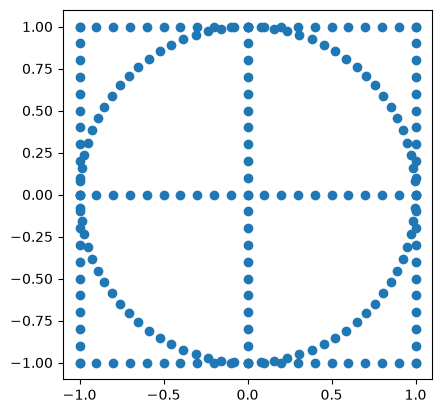

In [74]:
import numpy as np
import matplotlib.pyplot as plt

lv = np.linspace(-1, 1, 21); zv = np.zeros(21); ov = np.ones(21)
x_list = np.hstack([np.sin(np.linspace(0, 2*np.pi, 81)), zv, lv, lv, lv, ov, -ov])
y_list = np.hstack([np.cos(np.linspace(0, 2*np.pi, 81)), lv, zv, ov, -ov, lv, lv])
z_list = np.ones(207)

fig, ax = plt.subplots()
ax.set_aspect('equal', 'box')
ax.scatter(x_list, y_list)

Define intrinsic parameters

In [75]:
x0 = 0      # principal point in x-px-length
y0 = 0
a_x = 1.1     # focal length in x-px lengths
a_y = 1.0

# shear and rotation of sensor in relation to image coordinate system
shear_angle_theta = np.deg2rad(90)
sensor_rotation_phi = np.deg2rad(10)


In [76]:
# build matrices in homogenous coordinates

translation_matrix_T = np.array([
    [1, 0, x0],
    [0, 1, y0],
    [0, 0, 1]
])
dilation_D = np.array([
    [a_x, 0, 0],
    [0, a_y, 0],
    [0, 0, 1]
])
c = np.cos(sensor_rotation_phi)
s = np.sin(sensor_rotation_phi)
rotation_R = np.array([
    [c, s, 0],
    [-s, c, 0],
    [0, 0, 1]
])
shear_S = np.array([
    [1, - 1 / np.tan(shear_angle_theta), 0],
    [0, 1 / np.sin(shear_angle_theta), 0],
    [0, 0, 1]
])

# Resulting camera matrix
camera_matrix_K = translation_matrix_T @ rotation_R @ dilation_D @ shear_S


Define extrinsic parameters

In [77]:
# From world to camera coordinates

alpha = np.deg2rad(0)
beta = np.deg2rad(0)
# beta = np.deg2rad(20)
gamma = np.deg2rad(0)
# gamma = np.deg2rad(10)

translation_vector_t = np.array([0, 0, 0]).reshape((3,1))
# translation_vector_t = np.array([1, 0, 0]).reshape((3,1))


In [78]:
# build matrices in homogenous coordinates

def Rx(a):
    c, s = np.cos(a), np.sin(a)
    return np.array([[1, 0,  0],
                     [0, c, -s],
                     [0, s,  c]])

def Ry(b):
    c, s = np.cos(b), np.sin(b)
    return np.array([[ c, 0, s],
                     [ 0, 1, 0],
                     [-s, 0, c]])

def Rz(g):
    c, s = np.cos(g), np.sin(g)
    return np.array([[c, -s, 0],
                     [s,  c, 0],
                     [0,  0, 1]])

rotation_matrix_Rc = Rx(alpha) @ Ry(beta) @ Rz(gamma)

In [79]:
Xc = np.hstack((rotation_matrix_Rc, - rotation_matrix_Rc @ translation_vector_t))
Xc = np.vstack((Xc, np.array([0, 0, 0, 1])))

K_homo = np.hstack((camera_matrix_K, np.zeros((3, 1))))

total_transformation_P = K_homo @ Xc

Naive approach (looping over all points)

In [80]:
x_img_list = []
y_img_list = []
for x, y, z in zip(x_list, y_list, z_list):
    world_vector_homo = np.array([x, y, z, 1]).reshape((4, 1))
    image_vector_homo = total_transformation_P @ world_vector_homo

    x_img_list.append(image_vector_homo[0,0] / image_vector_homo[2,0])
    y_img_list.append(image_vector_homo[1,0] / image_vector_homo[2,0])


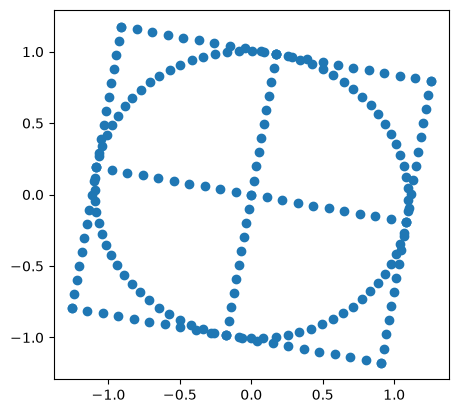

In [81]:
fig, ax = plt.subplots()
ax.set_aspect('equal', 'box')
ax.scatter(x_img_list, y_img_list)

## Lens (Radial) Distortion
A real lens adds radial distortion to the pinhole model. Because of the lens' axial symmetry it is a function of the radial distance only:

$$
\begin{pmatrix}x_d\\y_d\end{pmatrix}=L(\tilde r)\begin{pmatrix}\tilde x\\\tilde y\end{pmatrix},\qquad \tilde r=\sqrt{\tilde x^2+\tilde y^2}
$$
($\tilde x,\tilde y$: ideal undistorted point, $x_d,y_d$: actual point.)

**Correction** (distortion center $(x_c,y_c)$, usually near the principal point):

$$
\hat x = x_c + L(r)(x-x_c),\quad \hat y = y_c + L(r)(y-y_c),\quad r^2=(x-x_c)^2+(y-y_c)^2
$$

Common models for $L$:
- $L(r)=\dfrac{1}{1+k r^2}$
- Taylor expansion: $L(r)=1+\kappa_1 r+\kappa_2 r^2+\kappa_3 r^3+\dots$ (coefficients typically small)

**Calibration toolboxes:** Bouguet's Camera Calibration Toolbox (Matlab / OpenCV; lens distortion, stereo rigs), DLR CalDe (automatic chessboard corner detection, sub-pixel accuracy).

---
# 2. Spatial Representation of Digital Images

- An image = spatial distribution of **irradiance** on a plane; a computer stores it as an array of **pixels** (2D) or **voxels** (3D).
- **Resolution** is ambiguous: number of pixels (cameras) *or* pixel density (ppi/dpi, printers).
- **Quantization:** mapping the measured irradiance onto a limited number of discrete values (gray levels).

> ### ✏️ Task T5.4 (1P)
> Write a routine that reduces the number of gray values in a gray-scale image (e.g. `cube.png` converted to gray). Run it with $n=2,3,5,10$ gray values.

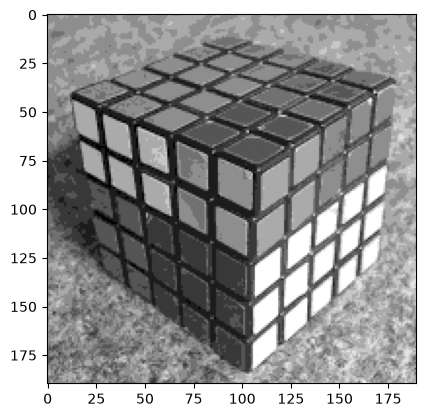

In [82]:
img = np.mean(plt.imread('cube.png'), axis=2)

quant_num = 10
img = np.round(img * (quant_num - 1)) / (quant_num - 1)

plt.figure()
plt.imshow(img, cmap='gray')

## Histograms
- **Image histogram:** number of pixels per tonal value → used to analyse quantization.
- **Color histogram:** distribution of colors, counting pixels per color range in a color space.
- Ways to visualize color distributions: 3 separate channel histograms · 2D histograms/scatter plots of channel pairs · 3D scatter plot · any of these in another color space.
- Tools: `plt.hist`, `np.histogram2d` (+ `plt.imshow`), `ax.scatter` with `projection='3d'`.

## Color Spaces
- Color images have 3 channels (human eye: 3 cone types). Standard space: **RGB**; others are used for printing/processing.
- **HSV** = hue, saturation, brightness value. With $r,g,b$ and $\max,\min$ over the three:

$$
h=\begin{cases}
0 & \max=\min\\
\left(60^\circ\cdot\frac{g-b}{\max-\min}+360^\circ\right)\bmod 360^\circ & \max=r\\
60^\circ\cdot\frac{b-r}{\max-\min}+120^\circ & \max=g\\
60^\circ\cdot\frac{r-g}{\max-\min}+240^\circ & \max=b
\end{cases}
\qquad
s=\begin{cases}0 & \max=0\\ 1-\frac{\min}{\max} & \text{otherwise}\end{cases}
\qquad v=\max
$$

Python: `matplotlib.colors.rgb_to_hsv(arr)`, inverse `hsv_to_rgb`.

> ### ✏️ Task T5.6 (2P)
> Convert an image (any image) to HSV with `matplotlib.colors.rgb_to_hsv(arr)` and plot the different components.

> ### ✏️ Task T5.9 (slide 40) (1P)
> Write a small routine that creates the colour-manipulated cube image shown on slide 40 from `cube.png`.

> ### ✏️ Task T5.7 (3P)
> Reproduce the three colour-manipulated cube images shown on slide 42. *Hint: use the HSV color space.*

## Multispectral vs. Hyperspectral
- **Multispectral** instrument: ~10–100 wavelength bands (discrete spectral bands per pixel)
- **Hyperspectral** instrument: ~100–1000s of bands (quasi-continuous spectrum per pixel)

## Signals by Dimension $D$ (number of parameters)

| $D$ | Signal | $g(\cdot)$ |
|---|---|---|
| 0 | single measurement | $g$ |
| 1 | time series / profile / spectrum | $g(t)$ / $g(x)$ / $g(\lambda)$ |
| 2 | image / time series of profiles / of spectra | $g(x,y)$ / $g(x,t)$ / $g(\lambda,t)$ |
| 3 | volumetric image / image sequence / hyperspectral image | $g(x,y,z)$ / $g(x,y,t)$ / $g(x,y,\lambda)$ |
| 4 | volumetric image sequence / hyperspectral image sequence | $g(x,y,z,t)$ / $g(x,y,\lambda,t)$ |
| 5 | hyperspectral volumetric image sequence | $g(x,y,z,\lambda,t)$ |

---
# 3. Wave Number Space and Fourier Transform

## Fourier Transform (image-processing convention)
Obtained from the $\omega$-form with $k=\omega/2\pi$ and splitting the $1/2\pi$ factor evenly:

$$
F(k)=\int_{-\infty}^{\infty} f(x)\,e^{-2\pi i k x}\,dx,\qquad
f(x)=\int_{-\infty}^{\infty} F(k)\,e^{2\pi i k x}\,dk
$$

## Discrete Fourier Transform (DFT)
**1-D**, vector of length $N$:

$$
\tilde f_k=\frac{1}{\sqrt N}\sum_{n=0}^{N-1} f_n\,e^{-2\pi i nk/N},\qquad
f_n=\frac{1}{\sqrt N}\sum_{k=0}^{N-1}\tilde f_k\,e^{2\pi i nk/N}
$$

**2-D**, $N\times M$ matrix (complex → complex):

$$
\tilde f_{k,l}=\frac{1}{\sqrt{NM}}\sum_{n=0}^{N-1}\sum_{m=0}^{M-1} f_{n,m}\,e^{-2\pi i nk/N}\,e^{-2\pi i ml/M}
$$
(inverse: same with $+$ sign in the exponents and sum over $k,l$.)

NumPy: `np.fft.fft`, `np.fft.fft2`, `np.fft.ifft2`, `np.fft.fftshift` (zero frequency to center), `np.abs` (amplitude), `np.angle` (phase).
*Note: NumPy's `fft` has no $1/\sqrt N$ factor (it is in `ifft` as $1/N$); use `norm="ortho"` for the symmetric convention above.*

## Properties
($f,g$ images; $\alpha,\beta$ complex scalars; $x,x_0,k,k_0$ vectors; $\mathcal F_{(f)}$ = transform of $f$; $A$ real invertible matrix; $R$ rotation matrix)

| Property | Statement |
|---|---|
| Linearity | $\mathcal F(\alpha f+\beta g)=\alpha\mathcal F(f)+\beta\mathcal F(g)$ ⇔ additivity + homogeneity of degree 1 |
| Translation | $\mathcal F(f(x-x_0))=e^{-2\pi i x_0 k}\,\mathcal F(f(x))$ |
| Modulation | $\mathcal F\!\left(e^{2\pi i x_0 k}f(x)\right)=\mathcal F_{(f)}(k-k_0)$ |
| Scaling | $\mathcal F(f(\alpha x))=\frac{1}{\lvert\alpha\rvert}\mathcal F_{(f)}(k/\alpha)$ |
| Affine | $\mathcal F(f(Ax))=\frac{1}{\lvert\det A\rvert}\mathcal F_{(f)}\!\left((A^{-1})^T k\right)$ |
| Rotation | $\mathcal F(f(Rx))=\mathcal F_{(f)}(Rk)$ |

Scaling / affine maps generally require **interpolating** the image (discrete case: exact only for integer $\alpha$).

> ### ✏️ Task T5.8 (1P)
> Prove that for a rotation ($f$ image, $\mathcal F_{(f)}$ its Fourier transform, $R$ rotation matrix) $\;\mathcal F(f(Rx))=\mathcal F_{(f)}(Rk)$.

*Proof:*

## Amplitude vs. Phase
$\tilde f$ is complex: $\tilde f = |\tilde f|\,e^{i\varphi}$.
- **Amplitude** $|\tilde f|$: how much of each spatial frequency is present (directional energy distribution).
- **Phase** $\varphi$: where the structures sit — it carries most of the visible image structure.
- Swapping phases between two images, $\;|\tilde f_1|\,e^{i\varphi_2}\;$ after inverse transform, resembles image 2 rather than image 1.

> ### ✏️ Task T5.9 (slide 57) (1P)
> Apply the 2-D DFT to a gray-scale image (`cube.png` or any image) and plot the amplitude and the phase of the complex result (hint: `np.angle`). Can you explain the structures you see?

## Fourier Filtering
Work on the **centered** spectrum $\tilde f_c$ = `fftshift(fft2(img))` and multiply with a mask $M$ (e.g. disc of radius $w$):

- **Low-pass:** $\tilde f_c\cdot M$ → smooth/blurred image (only low frequencies kept)
- **High-pass:** $\tilde f_c\cdot(1-M)$ → edges and fine detail
- Back-transform with `ifft2(ifftshift(...))`, take `np.abs`.
- **Edge enhancement:** $\;\text{lp}+a\cdot\text{hp}$ with $a>1$; the filter width $w$ controls which detail size is amplified.

> ### ✏️ Task T5.10 (3P)
> Calculate the DFT of an image and create another image of the same size with a centered box of ones (size 40) and zeros elsewhere. Multiply the DFT with this box image and with its inverse (1 − box). Back-transform both results and plot them. What do you notice?

> ### ✏️ Task T5.13 (2P)
> Apply the Fourier filter to an image. Add the low-pass and high-pass filtered images — what is the result? What do you get for low-pass + 1.5 × high-pass?

---
# 4. Time–Frequency Analysis

## Short-Time Fourier Transform (STFT)
The FT is localized in frequency only, not in time/space. STFT: window the signal (window function $w$, shift $\tau$) and transform each segment:

$$
F(\tau,\omega)=\int_{-\infty}^{\infty} f(t)\,w(t-\tau)\,e^{-i\omega t}\,dt
$$

Plot of $|F(\tau,\omega)|$ over time = **spectrogram** (waterfall plot).

- narrow window → good time resolution, poor frequency resolution
- wide window → poor time resolution, good frequency resolution
- Resolution is **fixed** for all frequencies — not ideal, since low frequencies need high frequency resolution, while high frequencies (short bursts) need high time resolution.

## Wavelet Transform (WT) — multiresolution analysis

$$
WT(\tau,s)=\frac{1}{\sqrt{|s|}}\int_{-\infty}^{\infty} f(t)\,\psi^{*}\!\left(\frac{t-\tau}{s}\right)dt
$$

- $\psi$: (mother) wavelet = basis and window function; $s$: scale ($\sim 1/\text{frequency}$); $\tau$: translation. Varying $s$ and $\tau$ changes width and center frequency of the window ("scaling").
- **Resolution:** high frequencies → good time / poor frequency resolution; low frequencies → good frequency / poor time resolution.
- Inverse (with admissibility constant $C_\psi$):
$\;f(t)=\frac{1}{C_\psi}\iint WT(\tau,s)\,\frac{1}{\sqrt{|s|}}\,\psi\!\left(\frac{t-\tau}{s}\right)\frac{d\tau\,ds}{s^2}$
- Location of the wavelet → location of events in time; shape → level of detail/resolution.
- **Sparsity:** for typical signals many wavelet coefficients are zero or very small.
- Mother wavelets: Haar, Morlet, Daubechies, Meyer, Coiflet, Mexican hat (Ricker), …

**Python (continuous WT):** `signal.cwt(data, signal.ricker, widths)` (removed in recent SciPy versions → use `pywt.cwt(data, widths, 'mexh')`).

## Discrete Wavelet Transform (DWT)
Uses a discrete set of scales and translations; decomposes the signal into a **mutually orthogonal** set of wavelets (main difference to CWT).

- The wavelet is built from a **scaling function** $\Phi$ satisfying the **dilation equation**
$$
\Phi(x)=\sum_{k=-\infty}^{\infty} a_k\,\Phi(Sx-k),\qquad S=2\text{ (usually)}
$$
- Normalized and orthogonal to its integer translations: $\displaystyle\int\Phi(x)\Phi(x+l)\,dx=\delta_{0,l}$
- A finite set of coefficients $a_k$ defines both scaling function and wavelet.
- **Haar:** scaling function = box function. **Daubechies** family: orthonormal, named by the number of nonzero $a_k$ (e.g. db4, db20).

## PyWavelets (`pywt`)

| Function | Purpose |
|---|---|
| `pywt.dwt(f, wavelet, mode)` | single-level DWT → `cA` (approximation, low freq.), `cD` (detail, high freq.); each of length ≈ N/2 |
| `pywt.idwt(cA, cD, wavelet)` | single-level inverse |
| `pywt.wavedec(data, wavelet, level)` | multilevel DWT → `[cA_n, cD_n, cD_n-1, …, cD1]` (= repeated `dwt` on `cA`) |
| `pywt.dwt2(img, wavelet)` | 2D DWT → `cA, (cH, cV, cD)` |
| `pywt.wavelist()` | all available wavelets (haar, db1-38, sym, coif, bior, dmey, mexh, morl, …) |

## 2D Wavelets
The WT is **separable**: apply it to rows and columns of an image separately. One level gives an approximation (low-pass in both directions) plus horizontal, vertical and diagonal detail images; the approximation can be decomposed recursively (multi-level).